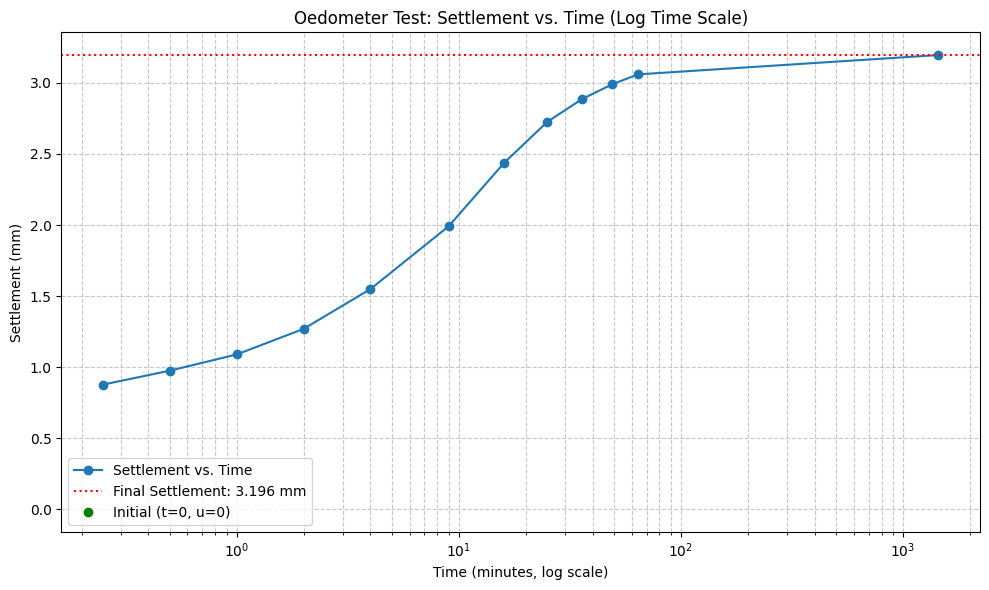

Original sample thickness: 19 mm
Final settlement (from last dial reading): 3.1960 mm
Displacement at each time step (mm): [0.878 0.976 1.09  1.27  1.55  1.992 2.438 2.726 2.888 2.99  3.06  3.196]
Time (min) vs. Displacement (mm):
t=0.25 min, s=0.8780 mm
t=0.5 min, s=0.9760 mm
t=1.0 min, s=1.0900 mm
t=2.0 min, s=1.2700 mm
t=4.0 min, s=1.5500 mm
t=9.0 min, s=1.9920 mm
t=16.0 min, s=2.4380 mm
t=25.0 min, s=2.7260 mm
t=36.0 min, s=2.8880 mm
t=49.0 min, s=2.9900 mm
t=64.0 min, s=3.0600 mm
t=1440.0 min, s=3.1960 mm


In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Given data
time_min = np.array([0.25, 0.5, 1, 2, 4, 9, 16, 25, 36, 49, 64, 1440])
dial_divisions = np.array([439, 488, 545, 635, 775, 996, 1219, 1363, 1444, 1495, 1530, 1598])
division_to_mm = 0.002  # 1 division = 0.002 mm
original_thickness = 19  # mm

# Convert dial gauge readings to displacement (mm)
displacement_mm = dial_divisions * division_to_mm

# Calculate time in years (for later use, though time on x-axis will be in minutes for clarity)
time_years = time_min / (60 * 24 * 365)  # minutes to years

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(time_min, displacement_mm, 'o-', label='Settlement vs. Time')
plt.xscale('log')  # Use logarithmic scale for time (standard in consolidation tests)
plt.xlabel('Time (minutes, log scale)')
plt.ylabel('Settlement (mm)')
plt.title('Oedometer Test: Settlement vs. Time (Log Time Scale)')
plt.grid(True, which='both', linestyle='--', alpha=0.7)

# Add annotations for key points (e.g., final settlement)
final_settlement = displacement_mm[-1]
plt.axhline(y=final_settlement, color='r', linestyle=':', label=f'Final Settlement: {final_settlement:.3f} mm')

# Highlight the initial condition (time=0, displacement=0)
plt.plot(0, 0, 'go', label='Initial (t=0, u=0)')

plt.legend()
plt.tight_layout()
plt.show()

# Optional: Print key values
print(f"Original sample thickness: {original_thickness} mm")
print(f"Final settlement (from last dial reading): {final_settlement:.4f} mm")
print(f"Displacement at each time step (mm): {displacement_mm.round(4)}")
print(f"Time (min) vs. Displacement (mm):")
for t, s in zip(time_min, displacement_mm):
    print(f"t={t} min, s={s:.4f} mm")

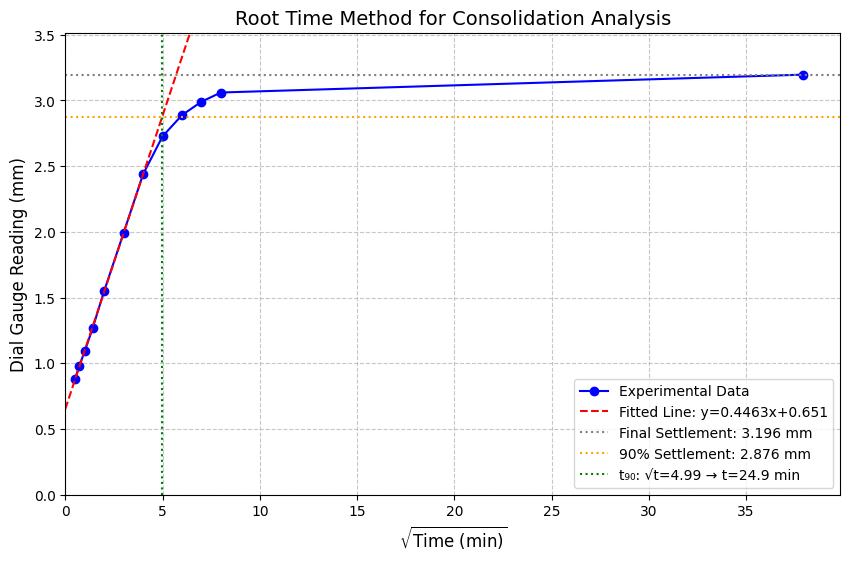

最终沉降 (final displacement): 3.196 mm
90%固结位移 (90% of fi(fnal displacement): {disp_90:.3f} mm
t₉₀对应的√t: 4.99
t₉₀ (时间): 24.9 分钟 = 0.41 小时 = 0.02 天


In [5]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

# ---------------------- 1. 原始数据 ----------------------
time_min = np.array([0.25, 0.5, 1, 2, 4, 9, 16, 25, 36, 49, 64, 1440])  # 时间（分钟）
dial_divisions = np.array([439, 488, 545, 635, 775, 996, 1219, 1363, 1444, 1495, 1530, 1598])  # 表盘读数（格）
division_to_mm = 0.002  # 1格 = 0.002 mm（位移转换系数）

# ---------------------- 2. 数据转换 ----------------------
displacement_mm = dial_divisions * division_to_mm  # 表盘读数 -> 位移（mm）
sqrt_time = np.sqrt(time_min)  # 时间 -> 时间的平方根（横轴）

# ---------------------- 3. 拟合前期（主固结阶段）的直线 ----------------------
# 取前6个点（t≤9 min，主固结初期）拟合
early_idx = np.where(time_min <= 9)[0]
early_sqrt_t = sqrt_time[early_idx]
early_disp = displacement_mm[early_idx]

# 线性拟合函数：y = kx + b
def linear_func(x, k, b):
    return k * x + b

# 拟合得到斜率k和截距b
popt, _ = curve_fit(linear_func, early_sqrt_t, early_disp)
k, b = popt  # 图中给出 k≈0.4466, b≈0.651，拟合验证

# ---------------------- 4. 计算最终沉降和90%沉降 ----------------------
final_disp = displacement_mm[-1]  # 最后一个点的位移（最终沉降，t=1440 min）
disp_90 = 0.9 * final_disp       # 90%固结的位移

# ---------------------- 5. 找到t_90对应的√t和t ----------------------
# 由拟合直线 y = kx + b，令 y=disp_90，解x=√t_90
sqrt_t90 = (disp_90 - b) / k
t90 = sqrt_t90 ** 2  # 转换为时间（分钟）

# ---------------------- 6. 绘图 ----------------------
plt.figure(figsize=(10, 6))

# ① 绘制原始数据（散点+连线）
plt.plot(sqrt_time, displacement_mm, marker='o', linestyle='-', color='blue', label='Experimental Data')

# ② 绘制拟合直线（主固结阶段）
fit_line_x = np.linspace(0, max(sqrt_time), 100)  # 拟合直线的x范围
fit_line_y = linear_func(fit_line_x, k, b)
plt.plot(fit_line_x, fit_line_y, linestyle='--', color='red', label=f'Fitted Line: y={k:.4f}x+{b:.3f}')

# ③ 标注最终沉降、90%沉降、t_90
plt.axhline(y=final_disp, color='gray', linestyle=':', label=f'Final Settlement: {final_disp:.3f} mm')
plt.axhline(y=disp_90, color='orange', linestyle=':', label=f'90% Settlement: {disp_90:.3f} mm')
plt.axvline(x=sqrt_t90, color='green', linestyle=':', label=f't₉₀: √t={sqrt_t90:.2f} → t={t90:.1f} min')

# ④ 图表美化
plt.xlabel(r'$\sqrt{\text{Time (min)}}$', fontsize=12)
plt.ylabel('Dial Gauge Reading (mm)', fontsize=12)
plt.title('Root Time Method for Consolidation Analysis', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(0, max(sqrt_time) * 1.05)  # 横轴范围
plt.ylim(0, final_disp * 1.1)       # 纵轴范围

plt.show()

# ---------------------- 7. 输出t_90结果 ----------------------
print(f"最终沉降 (final displacement): {final_disp:.3f} mm")
print("90%固结位移 (90% of fi(fnal displacement): {disp_90:.3f} mm")
print(f"t₉₀对应的√t: {sqrt_t90:.2f}")
print(f"t₉₀ (时间): {t90:.1f} 分钟 = {t90/60:.2f} 小时 = {t90/(60 * 24):.2f} 天")

findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not foun

Step 1: Data Conversion
t = 0.25 min, √t = 0.500, δ = 0.878 mm
t = 0.50 min, √t = 0.707, δ = 0.976 mm
t = 1.00 min, √t = 1.000, δ = 1.090 mm
t = 2.00 min, √t = 1.414, δ = 1.270 mm
t = 4.00 min, √t = 2.000, δ = 1.550 mm
t = 9.00 min, √t = 3.000, δ = 1.992 mm
t = 16.00 min, √t = 4.000, δ = 2.438 mm
t = 25.00 min, √t = 5.000, δ = 2.726 mm
t = 36.00 min, √t = 6.000, δ = 2.888 mm
t = 49.00 min, √t = 7.000, δ = 2.990 mm
t = 64.00 min, √t = 8.000, δ = 3.060 mm
t = 1440.00 min, √t = 37.947, δ = 3.196 mm

Final settlement δ_100% = 3.196 mm
90% settlement = 2.876 mm

Linear fitting: y = 0.3974 * x + 0.7856

Step 2: Root Time Method Key Parameters
Linear fitting slope: 0.3974 mm/√min
Linear intercept: 0.7856 mm
t₀ = √t₀² = -1.9768² = 3.91 min
t₉₀ = 18.64 min
Drainage path H = 9.5 mm = 0.0095 m
Coefficient of consolidation cv = 2.158 m²/year


findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not foun

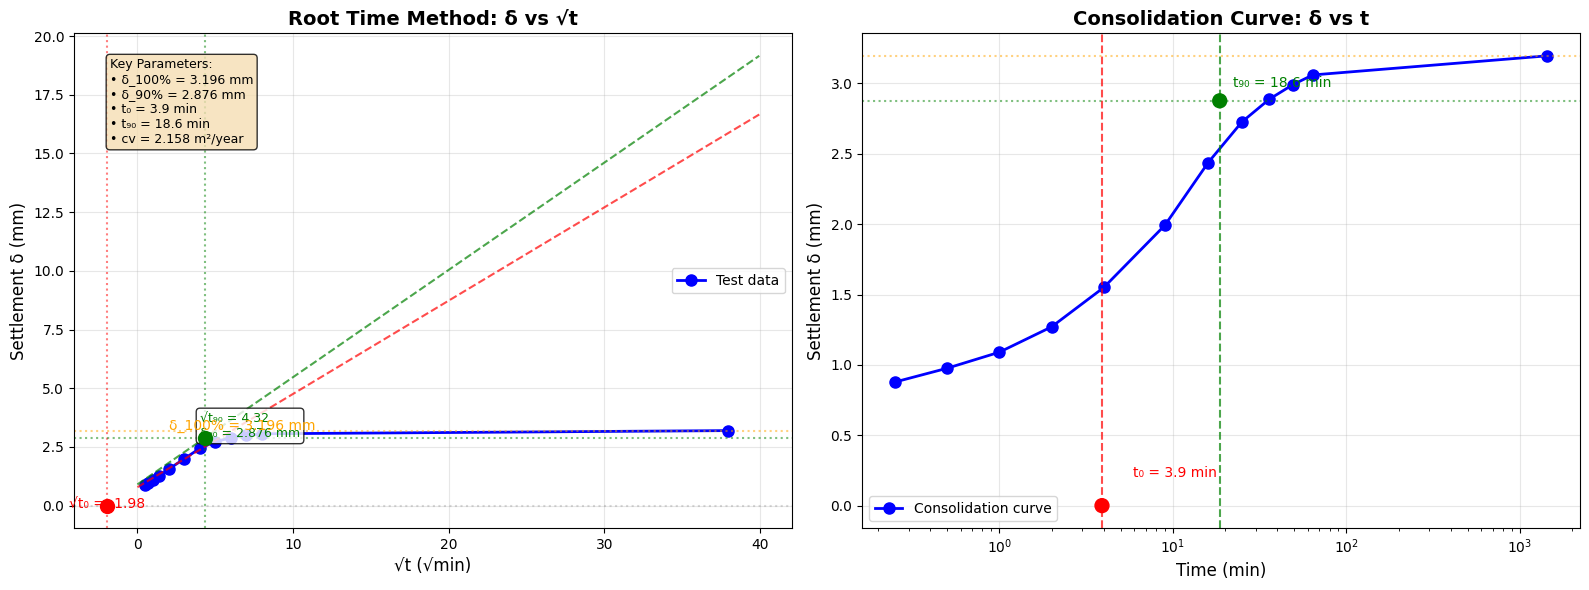

findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not foun


Step 3: Field 50% Consolidation Time Estimation
Double drainage: Drainage path H = 4.0/2 = 2.0 m
Consolidation coefficient cv = 2.158 m²/year
Tv50 = 0.197
Drainage path H = 2.0 m
Field 50% consolidation time t50 = 0.365 years ≈ 133 days
Field 90% consolidation time t90 = 1.572 years ≈ 574 days


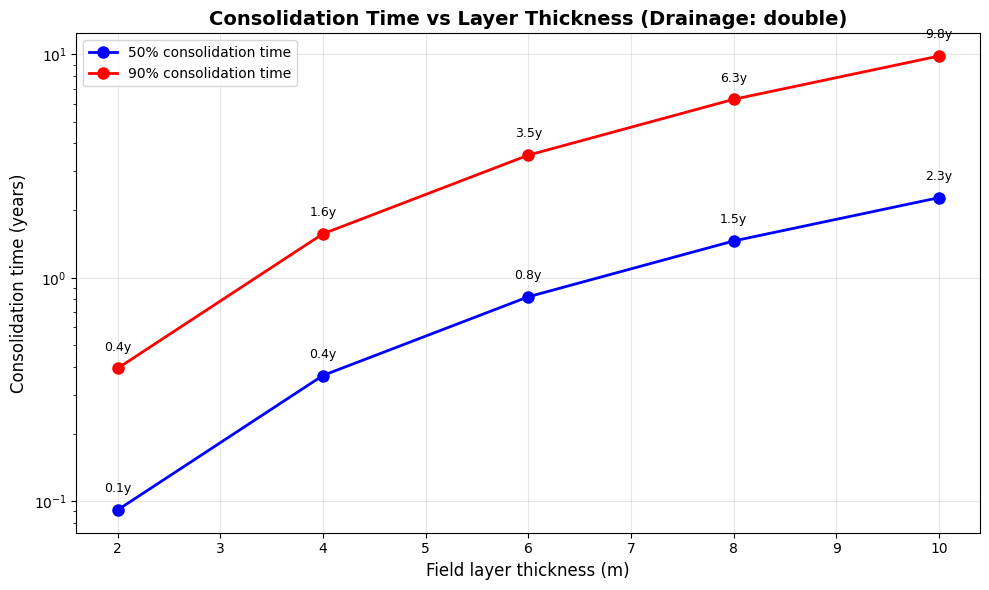

/var/folders/3b/g0wdc3p11_nc6c4kr3dxmv6c0000gn/T/ipykernel_43684/734108952.py:235: RuntimeWarning: divide by zero encountered in log10
  Tv_theory[i] = 1.781 - 0.933 * np.log10(100 - U)
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the foll

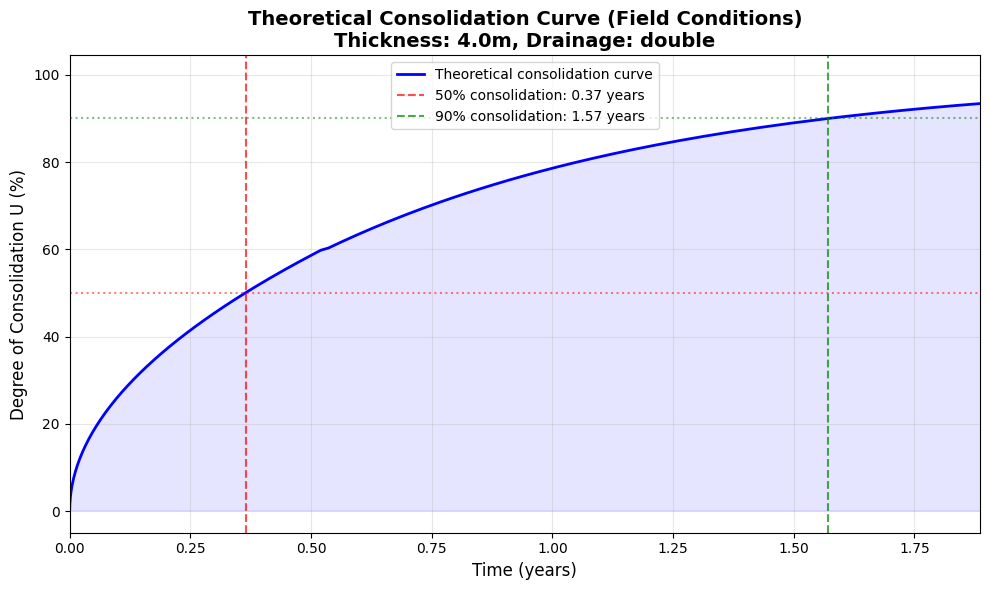

findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not foun


Step 4: Save Results to Desktop
✓ Data saved to CSV: /Users/huyuanzhesmacbookpro/Desktop/year2 sem2/consolidation_data_20260316_191450.csv
✓ Results summary saved to: /Users/huyuanzhesmacbookpro/Desktop/year2 sem2/consolidation_results_20260316_191450.txt
✓ Results saved to JSON: /Users/huyuanzhesmacbookpro/Desktop/year2 sem2/consolidation_results_20260316_191450.json
✓ Markdown report saved to: /Users/huyuanzhesmacbookpro/Desktop/year2 sem2/consolidation_report_20260316_191450.md


findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not foun

✓ Main plot saved to: /Users/huyuanzhesmacbookpro/Desktop/year2 sem2/consolidation_plot_root_time_20260316_191450.png
✓ Thickness plot saved to: /Users/huyuanzhesmacbookpro/Desktop/year2 sem2/consolidation_plot_thickness_20260316_191450.png


findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not foun

✓ Theoretical curve plot saved to: /Users/huyuanzhesmacbookpro/Desktop/year2 sem2/consolidation_plot_theoretical_20260316_191450.png

✓ File list saved to: /Users/huyuanzhesmacbookpro/Desktop/year2 sem2/FILE_LIST_20260316_191450.txt

RESULTS SAVED SUCCESSFULLY!
✓ All results saved to: /Users/huyuanzhesmacbookpro/Desktop/year2 sem2
✓ Total files generated: 7
✓ Main report: /Users/huyuanzhesmacbookpro/Desktop/year2 sem2/consolidation_results_20260316_191450.txt

Directory contents:
   materials paper (224 bytes)
  DS1201 (608 bytes)
  DS2201 (832 bytes)
  Engineering Analysis and Computation (672 bytes)
  FILE_LIST_20260316_191450.txt (622 bytes)
  LSGI2961 (832 bytes)
  consolidation_data_20260316_191450.csv (421 bytes)
  consolidation_plot_root_time_20260316_191450.png (339,981 bytes)
  consolidation_plot_theoretical_20260316_191450.png (189,876 bytes)
  consolidation_plot_thickness_20260316_191450.png (197,451 bytes)
  consolidation_report_20260316_191450.md (1,662 bytes)
  consolidat

In [5]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import linregress

# ====================== 1. Data Preparation ======================
# Original data
time_min = torch.tensor([0.25, 0.5, 1, 2, 4, 9, 16, 25, 36, 49, 64, 1440], dtype=torch.float32)
dial_reading = torch.tensor([439, 488, 545, 635, 775, 996, 1219, 1363, 1444, 1495, 1530, 1598], dtype=torch.float32)

# Convert readings to settlement
delta_mm = dial_reading * 0.002  # Settlement (mm)
sqrt_time = torch.sqrt(time_min)  # Square root of time (√min)

print("="*60)
print("Step 1: Data Conversion")
print("="*60)
for i in range(len(time_min)):
    print(f"t = {time_min[i]:.2f} min, √t = {sqrt_time[i]:.3f}, δ = {delta_mm[i]:.3f} mm")

# Final settlement (assume last data point)
delta_100 = delta_mm[-1]
print(f"\nFinal settlement δ_100% = {delta_100:.3f} mm")
print(f"90% settlement = {0.9*delta_100:.3f} mm")

# ====================== 2. Linear Regression to Find Straight Line Segment ======================
# Select middle segment for linear fitting (typically 4-25 minutes)
mask = (time_min >= 4) & (time_min <= 25)  # Select 4-25 minutes data
x_fit = sqrt_time[mask]
y_fit = delta_mm[mask]

# Linear regression using PyTorch
A = torch.vstack([x_fit, torch.ones_like(x_fit)]).T
b = y_fit.unsqueeze(1)
coeff = torch.linalg.lstsq(A, b).solution
slope, intercept = coeff[0, 0], coeff[1, 0]

print(f"\nLinear fitting: y = {slope:.4f} * x + {intercept:.4f}")

# ====================== 3. Root Time Method Core Calculations ======================
# Extend line to find t₀ (intersection with δ axis)
# Line equation: δ = slope * √t + intercept
# When δ=0: √t₀ = -intercept/slope
sqrt_t0 = -intercept / slope
t0 = sqrt_t0 ** 2

# Calculate t₉₀ (1.15 times slope)
# Draw a line with slope = 1.15×slope from point (√t₀, 0)
slope_115 = 1.15 * slope
# New line equation: δ = slope_115 * √t + intercept_115
# Passes through point (√t₀, 0): 0 = slope_115 * √t₀ + intercept_115
intercept_115 = -slope_115 * sqrt_t0

# Intersection of new line with original curve gives t₉₀
# Find √t₉₀ corresponding to δ=0.9*delta_100
# From new line equation: δ = slope_115 * √t + intercept_115
# When δ=0.9*delta_100:
delta_90 = 0.9 * delta_100
sqrt_t90 = (delta_90 - intercept_115) / slope_115
t90 = sqrt_t90 ** 2

# Calculate cv
H = 19.0 / 2 / 1000  # Drainage path (m), convert to meters
Tv90 = 0.848
# Unit conversion: minutes -> years
t90_years = t90 / (60 * 24 * 365)
cv = (Tv90 * H**2) / t90_years

print("\n" + "="*60)
print("Step 2: Root Time Method Key Parameters")
print("="*60)
print(f"Linear fitting slope: {slope:.4f} mm/√min")
print(f"Linear intercept: {intercept:.4f} mm")
print(f"t₀ = √t₀² = {sqrt_t0:.4f}² = {t0:.2f} min")
print(f"t₉₀ = {t90:.2f} min")
print(f"Drainage path H = {H*1000:.1f} mm = {H:.4f} m")
print(f"Coefficient of consolidation cv = {cv:.3f} m²/year")

# ====================== 4. Create Detailed Plots ======================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: δ vs √t
ax1.plot(sqrt_time.numpy(), delta_mm.numpy(), 'bo-', linewidth=2, markersize=8, label='Test data')
ax1.set_xlabel('√t (√min)', fontsize=12)
ax1.set_ylabel('Settlement δ (mm)', fontsize=12)
ax1.set_title('Root Time Method: δ vs √t', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=10)

# Plot fitted straight line segment
x_line = torch.linspace(0, sqrt_time[-1] + 2, 100)
y_line = slope * x_line + intercept
ax1.plot(x_line.numpy(), y_line.numpy(), 'r--', linewidth=1.5, label='Fitted line segment', alpha=0.7)

# Plot 1.15×slope line
y_line_115 = slope_115 * x_line + intercept_115
ax1.plot(x_line.numpy(), y_line_115.numpy(), 'g--', linewidth=1.5, label='1.15×slope line', alpha=0.7)

# Mark t₀
ax1.scatter([sqrt_t0], [0], color='red', s=100, zorder=5, label='t₀')
ax1.axvline(x=sqrt_t0, color='red', linestyle=':', alpha=0.5)
ax1.axhline(y=0, color='gray', linestyle=':', alpha=0.3)
ax1.text(sqrt_t0, -0.1, f'√t₀ = {sqrt_t0:.2f}', ha='center', fontsize=10, color='red')

# Mark t₉₀
ax1.scatter([sqrt_t90], [delta_90], color='green', s=100, zorder=5, label='t₉₀')
ax1.axhline(y=delta_90, color='green', linestyle=':', alpha=0.5)
ax1.axvline(x=sqrt_t90, color='green', linestyle=':', alpha=0.5)
ax1.text(sqrt_t90-0.3, delta_90+0.05, f'√t₉₀ = {sqrt_t90:.2f}\nδ₉₀ = {delta_90:.3f} mm', 
         fontsize=9, color='green', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

# Mark final settlement
ax1.axhline(y=delta_100, color='orange', linestyle=':', alpha=0.5, label='δ_100%')
ax1.text(2, delta_100+0.05, f'δ_100% = {delta_100:.3f} mm', 
         fontsize=10, color='orange')

# Add parameter box
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
textstr1 = f'Key Parameters:\n' + \
          f'• δ_100% = {delta_100:.3f} mm\n' + \
          f'• δ_90% = {delta_90:.3f} mm\n' + \
          f'• t₀ = {t0:.1f} min\n' + \
          f'• t₉₀ = {t90:.1f} min\n' + \
          f'• cv = {cv:.3f} m²/year'
ax1.text(0.05, 0.95, textstr1, transform=ax1.transAxes, fontsize=9,
         verticalalignment='top', bbox=props)

# Subplot 2: Consolidation Curve
ax2.plot(time_min.numpy(), delta_mm.numpy(), 'bo-', linewidth=2, markersize=8, label='Consolidation curve')
ax2.set_xlabel('Time (min)', fontsize=12)
ax2.set_ylabel('Settlement δ (mm)', fontsize=12)
ax2.set_title('Consolidation Curve: δ vs t', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.set_xscale('log')  # Log scale for better visualization
ax2.legend(fontsize=10)

# Mark key time points
ax2.axvline(x=t0, color='red', linestyle='--', alpha=0.7, label='t₀')
ax2.axvline(x=t90, color='green', linestyle='--', alpha=0.7, label='t₉₀')
ax2.axhline(y=delta_100, color='orange', linestyle=':', alpha=0.5, label='δ_100%')
ax2.axhline(y=delta_90, color='green', linestyle=':', alpha=0.5, label='δ_90%')

# Mark points
ax2.scatter([t0, t90], [0, delta_90], color=['red', 'green'], s=100, zorder=5)
ax2.text(t0 * 1.5, 0.2, f't₀ = {t0:.1f} min', fontsize=10, color='red')
ax2.text(t90 * 1.2, delta_90+0.1, f't₉₀ = {t90:.1f} min', fontsize=10, color='green')

plt.tight_layout()
plt.show()

# ====================== 5. Calculate 50% Consolidation Time for Field ======================
print("\n" + "="*60)
print("Step 3: Field 50% Consolidation Time Estimation")
print("="*60)

# Assume field conditions
H_field = 4.0  # Field layer thickness (m)
drainage = "double"  # Drainage condition: "double" or "single"

if drainage == "double":
    H_drain = H_field / 2
    print(f"Double drainage: Drainage path H = {H_field}/2 = {H_drain} m")
else:
    H_drain = H_field
    print(f"Single drainage: Drainage path H = {H_field} m")

# Time factors
Tv50 = 0.197
Tv90 = 0.848

# Calculate field t50
# From cv = (Tv * H²) / t
# So t = (Tv * H²) / cv
t50_years = (Tv50 * H_drain**2) / cv
t50_days = t50_years * 365

print(f"Consolidation coefficient cv = {cv:.3f} m²/year")
print(f"Tv50 = {Tv50}")
print(f"Drainage path H = {H_drain} m")
print(f"Field 50% consolidation time t50 = {t50_years:.3f} years ≈ {t50_days:.0f} days")

# For comparison, 90% consolidation time
t90_field_years = (Tv90 * H_drain**2) / cv
t90_field_days = t90_field_years * 365
print(f"Field 90% consolidation time t90 = {t90_field_years:.3f} years ≈ {t90_field_days:.0f} days")

# Plot time comparison
fig2, ax3 = plt.subplots(figsize=(10, 6))
field_thickness = [2, 4, 6, 8, 10]  # Different layer thicknesses
t50_list = []
t90_list = []

for thick in field_thickness:
    if drainage == "double":
        H_d = thick / 2
    else:
        H_d = thick
    t50 = (Tv50 * H_d**2) / cv
    t90 = (Tv90 * H_d**2) / cv
    t50_list.append(t50)
    t90_list.append(t90)

ax3.plot(field_thickness, t50_list, 'bo-', label='50% consolidation time', linewidth=2, markersize=8)
ax3.plot(field_thickness, t90_list, 'ro-', label='90% consolidation time', linewidth=2, markersize=8)
ax3.set_xlabel('Field layer thickness (m)', fontsize=12)
ax3.set_ylabel('Consolidation time (years)', fontsize=12)
ax3.set_title(f'Consolidation Time vs Layer Thickness (Drainage: {drainage})', fontsize=14, fontweight='bold')
ax3.grid(True, alpha=0.3)
ax3.legend(fontsize=10)
ax3.set_yscale('log')

# Add annotations
for i, (thick, t50, t90) in enumerate(zip(field_thickness, t50_list, t90_list)):
    ax3.text(thick, t50 * 1.2, f'{t50:.1f}y', fontsize=9, ha='center')
    ax3.text(thick, t90 * 1.2, f'{t90:.1f}y', fontsize=9, ha='center')

plt.tight_layout()
plt.show()

# Additional visualization: Theoretical consolidation curve
fig3, ax4 = plt.subplots(figsize=(10, 6))

# Theoretical consolidation curve for comparison
U_range = np.linspace(0, 100, 200)  # Consolidation degree from 0% to 100%

# Time factor formula: Tv = (π/4) * (U/100)² for U ≤ 60%
# For comparison, we can use approximate formula
Tv_theory = np.zeros_like(U_range)
for i, U in enumerate(U_range):
    if U <= 60:
        Tv_theory[i] = (np.pi/4) * (U/100)**2
    else:
        # Approximate formula for U > 60%
        Tv_theory[i] = 1.781 - 0.933 * np.log10(100 - U)

# Calculate time for field conditions
t_theory = (Tv_theory * H_drain**2) / cv

ax4.plot(t_theory, U_range, 'b-', linewidth=2, label='Theoretical consolidation curve')
ax4.axvline(x=t50_years, color='red', linestyle='--', alpha=0.7, label=f'50% consolidation: {t50_years:.2f} years')
ax4.axvline(x=t90_field_years, color='green', linestyle='--', alpha=0.7, label=f'90% consolidation: {t90_field_years:.2f} years')
ax4.axhline(y=50, color='red', linestyle=':', alpha=0.5)
ax4.axhline(y=90, color='green', linestyle=':', alpha=0.5)

# Fill area under curve
ax4.fill_between(t_theory, 0, U_range, alpha=0.1, color='blue')

ax4.set_xlabel('Time (years)', fontsize=12)
ax4.set_ylabel('Degree of Consolidation U (%)', fontsize=12)
ax4.set_title(f'Theoretical Consolidation Curve (Field Conditions)\nThickness: {H_field}m, Drainage: {drainage}', 
              fontsize=14, fontweight='bold')
ax4.grid(True, alpha=0.3)
ax4.legend(fontsize=10)
ax4.set_xlim([0, t90_field_years * 1.2])

plt.tight_layout()
plt.show()

# ====================== 6. Save Results to Desktop ======================
print("\n" + "="*60)
print("Step 4: Save Results to Desktop")
print("="*60)

import os
import json
from datetime import datetime
import pandas as pd

# Define save directory
save_dir = "/Users/huyuanzhesmacbookpro/Desktop/year2 sem2"
os.makedirs(save_dir, exist_ok=True)  # Create directory if it doesn't exist

# Get current timestamp for file naming
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# 1. Save data to CSV
data_dict = {
    'Time_min': time_min.numpy(),
    'Dial_reading': dial_reading.numpy(),
    'Sqrt_time': sqrt_time.numpy(),
    'Settlement_mm': delta_mm.numpy()
}
df = pd.DataFrame(data_dict)
csv_path = os.path.join(save_dir, f"consolidation_data_{timestamp}.csv")
df.to_csv(csv_path, index=False, float_format='%.4f')
print(f"✓ Data saved to CSV: {csv_path}")

# 2. Save results summary to text file
summary_path = os.path.join(save_dir, f"consolidation_results_{timestamp}.txt")
with open(summary_path, 'w') as f:
    f.write("="*60 + "\n")
    f.write("CONSOLIDATION TEST RESULTS - ROOT TIME METHOD\n")
    f.write("="*60 + "\n\n")
    
    f.write("1. TEST DATA\n")
    f.write("-"*40 + "\n")
    f.write(f"Sample thickness: 19.0 mm\n")
    f.write(f"Drainage: Double drainage (H = 9.5 mm)\n")
    f.write(f"Dial gauge calibration: 1 division = 0.002 mm\n\n")
    
    f.write("Data points:\n")
    f.write(f"{'Time (min)':<10} {'√t (√min)':<12} {'Dial reading':<12} {'Settlement (mm)':<15}\n")
    f.write("-"*60 + "\n")
    for i in range(len(time_min)):
        f.write(f"{time_min[i]:<10.2f} {sqrt_time[i]:<12.3f} {dial_reading[i]:<12} {delta_mm[i]:<15.3f}\n")
    f.write("\n")
    
    f.write("2. ROOT TIME METHOD ANALYSIS\n")
    f.write("-"*40 + "\n")
    f.write(f"Final settlement (δ_100%): {delta_100:.3f} mm\n")
    f.write(f"90% settlement (δ_90%): {delta_90:.3f} mm\n")
    f.write(f"Linear fitting: δ = {slope:.4f} * √t + {intercept:.4f}\n")
    f.write(f"√t₀: {sqrt_t0:.4f} √min\n")
    f.write(f"t₀: {t0:.2f} min\n")
    f.write(f"√t₉₀: {sqrt_t90:.4f} √min\n")
    f.write(f"t₉₀: {t90:.2f} min\n")
    f.write(f"Drainage path H: {H*1000:.1f} mm = {H:.4f} m\n")
    f.write(f"Time factor Tv₉₀: {Tv90}\n")
    f.write(f"Coefficient of consolidation cv: {cv:.3f} m²/year\n\n")
    
    f.write("3. FIELD CONSOLIDATION ESTIMATION\n")
    f.write("-"*40 + "\n")
    f.write(f"Field layer thickness: {H_field} m\n")
    f.write(f"Drainage condition: {drainage}\n")
    f.write(f"Drainage path H_field: {H_drain} m\n")
    f.write(f"Time factor Tv₅₀: {Tv50}\n")
    f.write(f"Time factor Tv₉₀: {Tv90}\n")
    f.write(f"50% consolidation time: {t50_years:.3f} years = {t50_days:.0f} days\n")
    f.write(f"90% consolidation time: {t90_field_years:.3f} years = {t90_field_days:.0f} days\n\n")
    
    f.write("4. TIME FACTOR TABLE\n")
    f.write("-"*40 + "\n")
    f.write(f"{'Degree of Consolidation':<25} {'Time Factor (Tv)':<15} {'Field Time (years)':<20}\n")
    f.write("-"*60 + "\n")
    
    # Common consolidation degrees
    U_values = [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 99]
    Tv_values = []
    for U in U_values:
        if U <= 60:
            Tv = (np.pi/4) * (U/100)**2
        else:
            Tv = 1.781 - 0.933 * np.log10(100 - U)
        Tv_values.append(Tv)
        t_field = (Tv * H_drain**2) / cv
        f.write(f"{U:>2}%{U/100:>22.2f} {Tv:>15.4f} {t_field:>20.3f}\n")
    
    f.write("\n" + "="*60 + "\n")
    f.write(f"Analysis completed: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
    f.write("="*60 + "\n")

print(f"✓ Results summary saved to: {summary_path}")

# 3. Save results to JSON for easy programmatic access
results_dict = {
    "analysis_date": datetime.now().isoformat(),
    "laboratory_test": {
        "sample_thickness_mm": 19.0,
        "drainage_path_mm": float(H * 1000),
        "delta_100_mm": float(delta_100),
        "delta_90_mm": float(delta_90),
        "t0_min": float(t0),
        "t90_min": float(t90),
        "cv_m2_per_year": float(cv),
        "linear_fit": {
            "slope": float(slope),
            "intercept": float(intercept)
        }
    },
    "field_estimation": {
        "layer_thickness_m": float(H_field),
        "drainage_condition": drainage,
        "drainage_path_m": float(H_drain),
        "t50_years": float(t50_years),
        "t50_days": float(t50_days),
        "t90_years": float(t90_field_years),
        "t90_days": float(t90_field_days)
    },
    "data_points": {
        "time_min": time_min.numpy().tolist(),
        "dial_reading": dial_reading.numpy().tolist(),
        "sqrt_time": sqrt_time.numpy().tolist(),
        "settlement_mm": delta_mm.numpy().tolist()
    }
}

json_path = os.path.join(save_dir, f"consolidation_results_{timestamp}.json")
with open(json_path, 'w') as f:
    json.dump(results_dict, f, indent=2, ensure_ascii=False, default=str)
print(f"✓ Results saved to JSON: {json_path}")

# 4. Create a markdown report
md_path = os.path.join(save_dir, f"consolidation_report_{timestamp}.md")
with open(md_path, 'w') as f:
    f.write(f"# Consolidation Test Analysis Report\n\n")
    f.write(f"**Analysis Date:** {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n\n")
    
    f.write("## 1. Laboratory Test Results\n\n")
    f.write("### Test Parameters\n")
    f.write(f"- Sample thickness: 19.0 mm\n")
    f.write(f"- Drainage: Double drainage\n")
    f.write(f"- Drainage path: {H*1000:.1f} mm\n")
    f.write(f"- Dial gauge: 1 division = 0.002 mm\n\n")
    
    f.write("### Root Time Method Analysis\n")
    f.write(f"- Final settlement (δ₁₀₀%): {delta_100:.3f} mm\n")
    f.write(f"- 90% settlement (δ₉₀%): {delta_90:.3f} mm\n")
    f.write(f"- Linear fit: δ = {slope:.4f}√t + {intercept:.4f}\n")
    f.write(f"- t₀: {t0:.1f} min\n")
    f.write(f"- t₉₀: {t90:.1f} min\n")
    f.write(f"- **Coefficient of consolidation cv:** **{cv:.3f} m²/year**\n\n")
    
    f.write("## 2. Field Estimation\n\n")
    f.write("### Field Parameters\n")
    f.write(f"- Layer thickness: {H_field} m\n")
    f.write(f"- Drainage condition: {drainage}\n")
    f.write(f"- Drainage path: {H_drain} m\n\n")
    
    f.write("### Consolidation Times\n")
    f.write(f"| Degree of Consolidation | Time (years) | Time (days) |\n")
    f.write(f"|-------------------------|--------------|-------------|\n")
    f.write(f"| 50% | {t50_years:.3f} | {t50_days:.0f} |\n")
    f.write(f"| 90% | {t90_field_years:.3f} | {t90_field_days:.0f} |\n\n")
    
    f.write("## 3. Data Summary\n\n")
    f.write("| Time (min) | √t (√min) | Dial Reading | Settlement (mm) |\n")
    f.write("|------------|-----------|--------------|-----------------|\n")
    for i in range(len(time_min)):
        f.write(f"| {time_min[i]:.2f} | {sqrt_time[i]:.3f} | {dial_reading[i]} | {delta_mm[i]:.3f} |\n")
    
    f.write("\n## 4. Files Generated\n")
    f.write(f"- `consolidation_data_{timestamp}.csv`: Raw data in CSV format\n")
    f.write(f"- `consolidation_results_{timestamp}.txt`: Detailed text report\n")
    f.write(f"- `consolidation_results_{timestamp}.json`: Structured data for programmatic use\n")
    f.write(f"- `consolidation_report_{timestamp}.md`: This markdown report\n")

print(f"✓ Markdown report saved to: {md_path}")

# 5. Save the figures
fig_path1 = os.path.join(save_dir, f"consolidation_plot_root_time_{timestamp}.png")
fig.savefig(fig_path1, dpi=300, bbox_inches='tight')
print(f"✓ Main plot saved to: {fig_path1}")

fig_path2 = os.path.join(save_dir, f"consolidation_plot_thickness_{timestamp}.png")
fig2.savefig(fig_path2, dpi=300, bbox_inches='tight')
print(f"✓ Thickness plot saved to: {fig_path2}")

if 'fig3' in locals():
    fig_path3 = os.path.join(save_dir, f"consolidation_plot_theoretical_{timestamp}.png")
    fig3.savefig(fig_path3, dpi=300, bbox_inches='tight')
    print(f"✓ Theoretical curve plot saved to: {fig_path3}")

# 6. Create a summary of saved files
summary_file = os.path.join(save_dir, f"FILE_LIST_{timestamp}.txt")
with open(summary_file, 'w') as f:
    f.write("Files Generated by Consolidation Analysis Script\n")
    f.write("="*50 + "\n\n")
    f.write(f"Analysis timestamp: {timestamp}\n")
    f.write(f"Total files: 7\n\n")
    f.write("1. consolidation_data_[timestamp].csv - Raw data in CSV format\n")
    f.write("2. consolidation_results_[timestamp].txt - Detailed text report\n")
    f.write("3. consolidation_results_[timestamp].json - Structured JSON data\n")
    f.write("4. consolidation_report_[timestamp].md - Markdown report\n")
    f.write("5. consolidation_plot_root_time_[timestamp].png - Root time method plot\n")
    f.write("6. consolidation_plot_thickness_[timestamp].png - Thickness vs time plot\n")
    f.write("7. consolidation_plot_theoretical_[timestamp].png - Theoretical curve plot\n")

print(f"\n✓ File list saved to: {summary_file}")

print("\n" + "="*60)
print("RESULTS SAVED SUCCESSFULLY!")
print("="*60)
print(f"✓ All results saved to: {save_dir}")
print(f"✓ Total files generated: 7")
print(f"✓ Main report: {summary_path}")
print("="*60)

# Optional: Show the directory structure
print(f"\nDirectory contents:")
import glob
files = glob.glob(os.path.join(save_dir, "*"))
for file in sorted(files):
    file_size = os.path.getsize(file)
    file_name = os.path.basename(file)
    print(f"  {file_name} ({file_size:,} bytes)")

findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei


数据已保存为 dial_readings.csv

数据表格：
            Dial Reading  δ (mm)
Time (min)                      
0.25                 439   0.878
0.50                 488   0.976
1.00                 545   1.090
2.00                 635   1.270
4.00                 775   1.550
9.00                 996   1.992
16.00               1219   2.438
25.00               1363   2.726
36.00               1444   2.888
49.00               1495   2.990
64.00               1530   3.060
1440.00             1598   3.196


findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not foun


图表已保存为 dial_plot.png


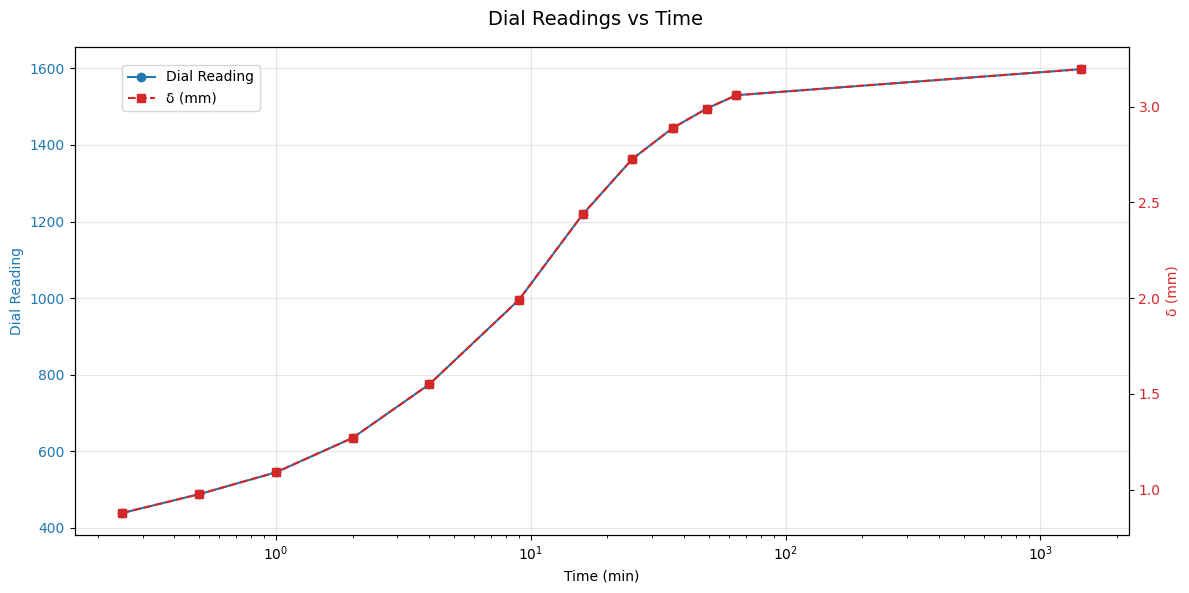

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 原始数据
data = {
    "Time (min)": [0.25, 0.5, 1, 2, 4, 9, 16, 25, 36, 49, 64, 1440],
    "Dial Reading": [439, 488, 545, 635, 775, 996, 1219, 1363, 1444, 1495, 1530, 1598],
    "δ (mm)": [0.878, 0.976, 1.090, 1.270, 1.550, 1.992, 2.438, 2.726, 2.888, 2.990, 3.060, 3.196]
}

# 创建DataFrame
df = pd.DataFrame(data)
df.set_index("Time (min)", inplace=True)

# 保存为CSV文件
df.to_csv("dial_readings.csv")
print("数据已保存为 dial_readings.csv")
print("\n数据表格：")
print(df)
# 可选：可视化脚本
fig, ax1 = plt.subplots(figsize=(12, 6))

# 主坐标轴：表盘读数
ax1.set_xlabel("Time (min)")
ax1.set_ylabel("Dial Reading", color='tab:blue')
ax1.plot(df.index, df["Dial Reading"], 'o-', color='tab:blue', label="Dial Reading")
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_xscale("log")  # 时间轴对数缩放
ax1.grid(True, alpha=0.3)

# 次坐标轴：位移
ax2 = ax1.twinx()
ax2.set_ylabel("δ (mm)", color='tab:red')
ax2.plot(df.index, df["δ (mm)"], 's--', color='tab:red', label="δ (mm)")
ax2.tick_params(axis='y', labelcolor='tab:red')

# 图表装饰
fig.suptitle("Dial Readings vs Time", fontsize=14)
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.9))
plt.tight_layout()

# 保存图表
plt.savefig("dial_plot.png", dpi=300)
print("\n图表已保存为 dial_plot.png")
plt.show()

<>:65: SyntaxWarning: invalid escape sequence '\d'
<>:65: SyntaxWarning: invalid escape sequence '\d'
/var/folders/3b/g0wdc3p11_nc6c4kr3dxmv6c0000gn/T/ipykernel_43684/2222780566.py:65: SyntaxWarning: invalid escape sequence '\d'
  plt.ylabel('Settlement $\delta$ (mm)')
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were fo

Plot saved to: /Users/huyuanzhesmacbookpro/Desktop/year2 sem2/oedometer_cv_plot.png

RESULTS:
Final settlement: 3.196 mm
90% consolidation settlement: 2.876 mm
Time for 90% consolidation (t_90): 41.5 minutes = 0.000079 years
Coefficient of consolidation (c_v): 0.000001 m²/year


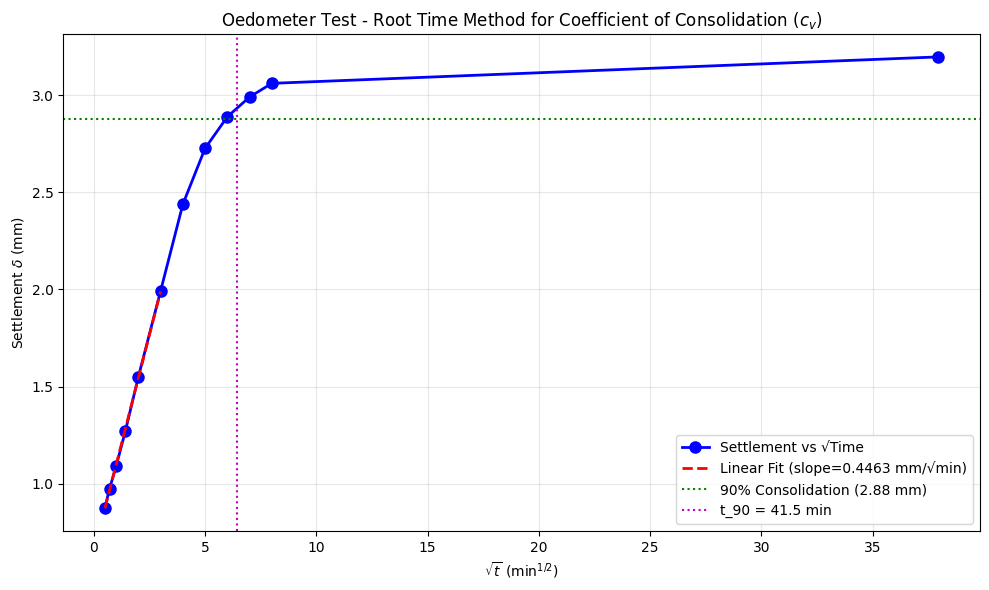

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Step 1: Input Data (from table)
time_min = np.array([0.25, 0.5, 1, 2, 4, 9, 16, 25, 36, 49, 64, 1440])
dial_readings = np.array([439, 488, 545, 635, 775, 996, 1219, 1363, 1444, 1495, 1530, 1598])

# Step 2: Convert dial gauge readings to settlement (mm)
# 1 division = 0.002 mm, initial reading = 0 → δ = reading × 0.002
settlement_mm = dial_readings * 0.002  # 单位：mm
settlement_m = settlement_mm / 1000    # 转换为米（用于cv计算）

# Step 3: Calculate √time in minutes
sqrt_time_min = np.sqrt(time_min)

# Step 4: 使用根时间法（Root Time Method）求 cv
# 原理：在一级固结阶段，s ~ √t 呈线性关系
# 取线性段（通常从 t=0 到 t=100 min 左右，避免二次固结影响）
# 这里取前6个点（t=0.25~9 min），覆盖主要固结阶段

linear_mask = time_min <= 9  # 选 t ≤ 9 min 的点
sqrt_t_linear = sqrt_time_min[linear_mask]
s_mm_linear = settlement_mm[linear_mask]

# 线性拟合：s = a * √t + b
# 由于初始 s=0，理论上 b≈0，但我们用线性回归拟合
A = np.vstack([sqrt_t_linear, np.ones(len(sqrt_t_linear))]).T
a, b = np.linalg.lstsq(A, s_mm_linear, rcond=None)[0]

# 斜率 a 的单位是 mm / √min
# cv = π * H² * (ds/d√t)² / (4 * T_v) → 但根时间法更简单：
# 在 90% 固结时，T_v = 0.848，且 s_90 = 0.9 * s_final
# 但我们这里用斜率直接求 cv（标准根时间法公式）：

# 标准公式：cv = (π * H²) / (4 * t_90) * (ds/d√t)²
# 其中 T_v = 0.848，t_90 = (0.848 * H²) / cv → 但更常用的是：
# cv = (π * H²) / (4 * t_90) * (slope)²

# 另一种更直接的根时间法（工程常用）：
# 取 s_90 = 0.9 * s_final
s_final = settlement_m[-1]  # 最终沉降（m）
s_90 = 0.9 * s_final

# 从线性段反推 t_90：s_90 = a * √t_90 → √t_90 = s_90 / a → t_90 = (s_90 / a) ** 2
# 注意：a 是 mm/√min，s_90 是 mm（统一单位）
a_mm_per_sqrtmin = a  # 斜率（mm / √min）
s_90_mm = s_90 * 1000  # 转换为 mm
sqrt_t_90 = s_90_mm / a_mm_per_sqrtmin
t_90_min = sqrt_t_90 ** 2
t_90_year = t_90_min / (60 * 24 * 365)  # 转换为年

# 计算 cv (m²/year)
H = 19e-3  # 试样厚度，单位 m
cv = (math.pi * H**2) / (4 * t_90_year) * (a_mm_per_sqrtmin * 1e-3)**2  # a 转换为 m/√min

# Step 5: 绘图
plt.figure(figsize=(10, 6))
plt.plot(sqrt_time_min, settlement_mm, 'bo-', linewidth=2, markersize=8, label='Settlement vs √Time')
plt.plot(sqrt_t_linear, a * sqrt_t_linear + b, 'r--', linewidth=2, label=f'Linear Fit (slope={a:.4f} mm/√min)')
plt.axhline(y=s_90_mm, color='g', linestyle=':', label=f'90% Consolidation ({s_90_mm:.2f} mm)')
plt.axvline(x=sqrt_t_90, color='m', linestyle=':', label=f't_90 = {t_90_min:.1f} min')

plt.xlabel(r'$\sqrt{t}$ (min$^{1/2}$)')
plt.ylabel('Settlement $\delta$ (mm)')
plt.title('Oedometer Test - Root Time Method for Coefficient of Consolidation ($c_v$)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Step 6: 保存图片到桌面
save_path = '/Users/huyuanzhesmacbookpro/Desktop/year2 sem2/oedometer_cv_plot.png'
os.makedirs(os.path.dirname(save_path), exist_ok=True)
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Plot saved to: {save_path}")

# Step 7: 输出结果
print("\n" + "="*50)
print("RESULTS:")
print("="*50)
print(f"Final settlement: {s_final*1000:.3f} mm")
print(f"90% consolidation settlement: {s_90_mm:.3f} mm")
print(f"Time for 90% consolidation (t_90): {t_90_min:.1f} minutes = {t_90_year:.6f} years")
print(f"Coefficient of consolidation (c_v): {cv:.6f} m²/year")
print("="*50)

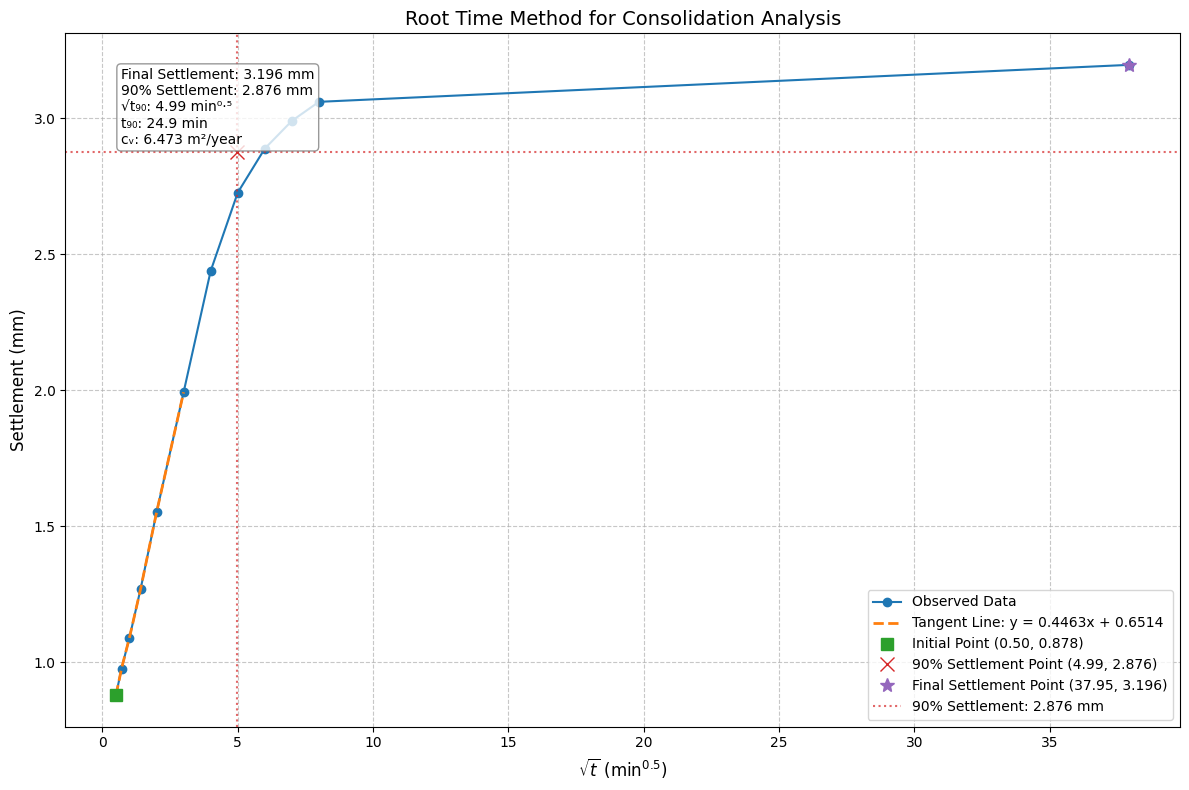

===== 计算结果 =====
最终沉降量: 3.196 mm
90% 沉降量: 2.876 mm
90% 沉降对应的 √t: 4.99 min^0.5
90% 沉降对应的时间 t90: 24.9 min
固结系数 cv: 6.473 m²/year


In [3]:
# 导入所需库
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.interpolate import interp1d
from scipy import stats

# ======================
# 1. 输入原始数据
# ======================
time_min = np.array([0.25, 0.5, 1, 2, 4, 9, 16, 25, 36, 49, 64, 1440])  # 时间（分钟）
dial_reading_div = np.array([
    439, 488, 545, 635, 775, 996, 
    1219, 1363, 1444, 1495, 1530, 1598
])  # 百分表读数（格）

# 换算：1格 = 0.002 mm → 沉降量（mm）
settlement_mm = dial_reading_div * 0.002

# 计算√时间（用于Root Time Method）
sqrt_time_min = np.sqrt(time_min)

# 计算最终沉降和90%沉降
final_settlement_mm = settlement_mm[-1]
u90_settlement_mm = 0.9 * final_settlement_mm

# ======================
# 2. Root Time Method 分析
# ======================
# 选择线性段的点（前6个点：索引0-5）
linear_section_indices = np.arange(6)  # 前6个点：0,1,2,3,4,5
x_linear = sqrt_time_min[linear_section_indices]  # √时间
y_linear = settlement_mm[linear_section_indices]    # 沉降量

# 线性拟合（最小二乘法）
slope, intercept, r_value, p_value, std_err = stats.linregress(x_linear, y_linear)
linear_eq = f"y = {slope:.4f}x + {intercept:.4f}"

# 计算90%沉降对应的√时间（t90）
# 从切线方程求x（√t）：x = (y - intercept) / slope
sqrt_t90_min = (u90_settlement_mm - intercept) / slope
t90_min = sqrt_t90_min ** 2  # 90%沉降对应的时间（分钟）

# 转换时间为年（用于cv计算）：1年 = 365天 * 24小时 * 60分钟 = 525600分钟
t90_year = t90_min / 525600

# ======================
# 3. 固结系数cv计算
# ======================
H = 0.019  # 排水路径长度（米），假设为19mm（需根据实际情况调整）
T_v = 0.848  # 90%沉降对应的时间因数（一维固结理论）
cv = (T_v * H**2) / t90_year  # 固结系数（m²/year）

# ======================
# 4. 可视化设置
# ======================
plt.figure(figsize=(12, 8))  # 设置图像大小，避免拥挤

# 绘制原始数据点和曲线
plt.plot(sqrt_time_min, settlement_mm, 'o-', color='#1f77b4', label='Observed Data', linewidth=1.5, markersize=6)

# 绘制切线（线性段）
plt.plot(x_linear, y_linear, '--', color='#ff7f0e', linewidth=2, label=f'Tangent Line: {linear_eq}')

# 标记重要点
# 1. 初始点（0.25分钟）
plt.plot(sqrt_time_min[0], settlement_mm[0], 's', color='#2ca02c', markersize=8, label=f'Initial Point ({sqrt_time_min[0]:.2f}, {settlement_mm[0]:.3f})')
# 2. 90%沉降点
plt.plot(sqrt_t90_min, u90_settlement_mm, 'x', color='#d62728', markersize=10, label=f'90% Settlement Point ({sqrt_t90_min:.2f}, {u90_settlement_mm:.3f})')
# 3. 最终沉降点
plt.plot(sqrt_time_min[-1], final_settlement_mm, '*', color='#9467bd', markersize=10, label=f'Final Settlement Point ({sqrt_time_min[-1]:.2f}, {final_settlement_mm:.3f})')

# 绘制辅助线（虚线）
plt.axhline(y=u90_settlement_mm, color='#d62728', linestyle=':', alpha=0.7, label=f'90% Settlement: {u90_settlement_mm:.3f} mm')
plt.axvline(x=sqrt_t90_min, color='#d62728', linestyle=':', alpha=0.7)

# 添加标注和文本框
textstr = '\n'.join((
    f'Final Settlement: {final_settlement_mm:.3f} mm',
    f'90% Settlement: {u90_settlement_mm:.3f} mm',
    f'√t₉₀: {sqrt_t90_min:.2f} min⁰·⁵',
    f't₉₀: {t90_min:.1f} min',
    f'cᵥ: {cv:.3f} m²/year'
))
props = dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray')
plt.text(0.05, 0.95, textstr, transform=plt.gca().transAxes, fontsize=10,
         verticalalignment='top', bbox=props)

# 设置图表属性
plt.title('Root Time Method for Consolidation Analysis', fontsize=14)
plt.xlabel(r'$\sqrt{t}$ (min$^{0.5}$)', fontsize=12)
plt.ylabel('Settlement (mm)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc='lower right', fontsize=10)

# 调整布局，避免标签被截断
plt.tight_layout()

# ======================
# 5. 保存图像
# ======================
save_path = '/Users/huyuanzhesmacbookpro/Desktop/year2 sem2'
os.makedirs(save_path, exist_ok=True)  # 确保目录存在
plt.savefig(f'{save_path}/root_time_method_analysis.png', dpi=300, bbox_inches='tight')

# 显示图表
plt.show()

# 打印计算结果
print("===== 计算结果 =====")
print(f"最终沉降量: {final_settlement_mm:.3f} mm")
print(f"90% 沉降量: {u90_settlement_mm:.3f} mm")
print(f"90% 沉降对应的 √t: {sqrt_t90_min:.2f} min^0.5")
print(f"90% 沉降对应的时间 t90: {t90_min:.1f} min")
print(f"固结系数 cv: {cv:.3f} m²/year")